**Step 1: Dataset Loading and Initial Inspection**

In [1]:
import pandas as pd

df = pd.read_csv("AB Testing Data.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (72248, 12)

Column Names:
['user_id', 'timestamp', 'group', 'landing_page', 'converted', 'age', 'gender', 'location', 'session_duration', 'pages_visited', 'device_type', 'purchase_amount']

First 5 Rows:


,user_id,timestamp,group,landing_page,converted,age,gender,location,session_duration,pages_visited,device_type,purchase_amount
0,U1,2025-08-02 15:27:54.137058,control,old_page,0.0,37.0,Male,Pakistan,3.69,4.0,Mobile,0.0
1,U2,2024-04-22 10:22:51.712050,treatment,new_page,0.0,31.0,Female,UK,1.29,3.0,Desktop,0.0
2,U3,2024-08-14 21:35:11.135894,treatment,new_page,0.0,38.0,Male,US,3.72,5.0,Desktop,0.0
3,U4,2025-03-19 03:28:51.120807,treatment,new_page,0.0,28.0,Female,India,7.76,2.0,Mobile,0.0
4,U5,2024-12-22 13:13:17.973162,control,old_page,0.0,33.0,Male,Australia,6.78,6.0,Mobile,0.0


**Step 2 – Data Quality and Randomization Check**

In [2]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Check duplicate user IDs
print("Duplicate User IDs:", df["user_id"].duplicated().sum())

# Check A/B testing groups
print("\nGroup Distribution:")
print(df["group"].value_counts())

# Check landing pages
print("\nLanding Page Distribution:")
print(df["landing_page"].value_counts())

# Check group and landing page mapping
print("\nGroup vs Landing Page:")
print(pd.crosstab(df["group"], df["landing_page"]))

# Check conversion values
print("\nConversion Values:")
print(df["converted"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72248 entries, 0 to 72247
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           72248 non-null  object 
 1   timestamp         72248 non-null  object 
 2   group             72248 non-null  object 
 3   landing_page      72247 non-null  object 
 4   converted         72247 non-null  float64
 5   age               72247 non-null  float64
 6   gender            72247 non-null  object 
 7   location          72247 non-null  object 
 8   session_duration  72247 non-null  float64
 9   pages_visited     72247 non-null  float64
 10  device_type       72247 non-null  object 
 11  purchase_amount   72247 non-null  float64
dtypes: float64(5), object(7)
memory usage: 6.6+ MB

Missing Values:
user_id             0
timestamp           0
group               0
landing_page        1
converted           1
age                 1
gender     

**Step 3 – Inspect Missing Record**

In [3]:
# Display rows containing missing values
missing_rows = df[df.isnull().any(axis=1)]

print("Number of incomplete rows:", len(missing_rows))

display(missing_rows)

Number of incomplete rows: 1


,user_id,timestamp,group,landing_page,converted,age,gender,location,session_duration,pages_visited,device_type,purchase_amount
72247,U72248,2024-11-07 10:18:40.341082,treatment,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Step 4 – Remove Incomplete Record**

In [4]:
# Remove rows containing missing values
df_clean = df.dropna().copy()

# Verify cleaned dataset
print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum().sum())

print("\nGroup Distribution After Cleaning:")
print(df_clean["group"].value_counts())

Original Dataset Shape: (72248, 12)
Cleaned Dataset Shape: (72247, 12)

Missing Values After Cleaning:
0

Group Distribution After Cleaning:
group
treatment    36132
control      36115
Name: count, dtype: int64


**Step 5 – Calculate Conversion Rate**

In [5]:
# Calculate total users and conversions for each group
conversion_summary = df_clean.groupby("group").agg(
    total_users=("converted", "count"),
    total_conversions=("converted", "sum")
)

# Calculate conversion rate in percentage
conversion_summary["conversion_rate"] = (
    conversion_summary["total_conversions"] /
    conversion_summary["total_users"]
) * 100

print("Conversion Rate Summary:")
display(conversion_summary)

Conversion Rate Summary:


,total_users,total_conversions,conversion_rate
group,,,
control,36115,4302.0,11.911948
treatment,36132,6411.0,17.743275


**Step 6 – Formulate Hypothese**s

In [6]:
# Null Hypothesis (H0):
# New page conversion rate is less than or equal to old page.

# Alternative Hypothesis (H1):
# New page conversion rate is greater than old page.

H0 = "p_treatment <= p_control"
H1 = "p_treatment > p_control"

print("Null Hypothesis (H0):", H0)
print("Alternative Hypothesis (H1):", H1)

Null Hypothesis (H0): p_treatment <= p_control
Alternative Hypothesis (H1): p_treatment > p_control


**Step 7 – Two-Proportion Z-Test**

In [7]:
from statsmodels.stats.proportion import proportions_ztest

# Get conversions and total users
control_conversions = int(
    conversion_summary.loc["control", "total_conversions"]
)
treatment_conversions = int(
    conversion_summary.loc["treatment", "total_conversions"]
)

control_users = int(
    conversion_summary.loc["control", "total_users"]
)
treatment_users = int(
    conversion_summary.loc["treatment", "total_users"]
)

# Perform Two-Proportion Z-Test
z_stat, p_value = proportions_ztest(
    [treatment_conversions, control_conversions],
    [treatment_users, control_users],
    alternative="larger"
)

print("Z-Statistic:", z_stat)
print("P-Value:", p_value)

# Decision
alpha = 0.05

if p_value < alpha:
    print("\nReject Null Hypothesis (H0)")
    print("The new page has a significantly higher conversion rate.")
else:
    print("\nFail to Reject Null Hypothesis (H0)")
    print("There is not enough evidence that the new page is better.")

Z-Statistic: 22.052303856987553
P-Value: 4.5391322934560385e-108

Reject Null Hypothesis (H0)
The new page has a significantly higher conversion rate.


**Step 8 – Confidence Interval (95%)**

In [8]:
from statsmodels.stats.proportion import proportion_confint

# Calculate 95% confidence interval for control group
control_ci = proportion_confint(
    control_conversions,
    control_users,
    alpha=0.05,
    method="wilson"
)

# Calculate 95% confidence interval for treatment group
treatment_ci = proportion_confint(
    treatment_conversions,
    treatment_users,
    alpha=0.05,
    method="wilson"
)

print("Control Group 95% CI:",
      control_ci[0] * 100, "% to", control_ci[1] * 100, "%")

print("Treatment Group 95% CI:",
      treatment_ci[0] * 100, "% to", treatment_ci[1] * 100, "%")

Control Group 95% CI: 11.581909199955138 % to 12.250088480907754 %
Treatment Group 95% CI: 17.35279279179561 % to 18.140614697930708 %


**Step 9 – Visualize Confidence Intervals**

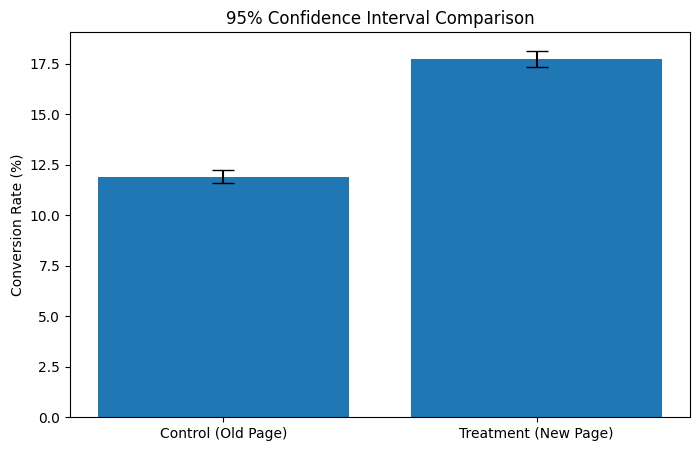

In [9]:
import matplotlib.pyplot as plt

# Conversion rates
rates = [
    conversion_summary.loc["control", "conversion_rate"],
    conversion_summary.loc["treatment", "conversion_rate"]
]

# Confidence interval errors
lower_errors = [
    rates[0] - control_ci[0] * 100,
    rates[1] - treatment_ci[0] * 100
]

upper_errors = [
    control_ci[1] * 100 - rates[0],
    treatment_ci[1] * 100 - rates[1]
]

# Plot
plt.figure(figsize=(8, 5))

plt.bar(
    ["Control (Old Page)", "Treatment (New Page)"],
    rates,
    yerr=[lower_errors, upper_errors],
    capsize=8
)

plt.ylabel("Conversion Rate (%)")
plt.title("95% Confidence Interval Comparison")
plt.show()

**Step 10 – Chi-Square Test**

In [10]:
from scipy.stats import chi2_contingency

# Create a contingency table
device_table = pd.crosstab(
    df_clean["device_type"],
    df_clean["converted"]
)

print("Device Type vs Conversion Table:")
display(device_table)

# Perform Chi-Square Test
chi2_stat, p_value, dof, expected = chi2_contingency(device_table)

print("\nChi-Square Statistic:", chi2_stat)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

# Decision
if p_value < 0.05:
    print("\nReject H0: Device type and conversion are significantly associated.")
else:
    print("\nFail to Reject H0: No significant association found.")

Device Type vs Conversion Table:


converted,0.0,1.0
device_type,,
Desktop,36943,6535
Mobile,21489,3623
Tablet,3102,555



Chi-Square Statistic: 4.955820877276512
P-Value: 0.08391839515073546
Degrees of Freedom: 2

Fail to Reject H0: No significant association found.


**Step 11 – Independent T-Test (Session Duration)**

In [11]:
from scipy.stats import ttest_ind

# Separate session duration for both groups
control_duration = df_clean[
    df_clean["group"] == "control"
]["session_duration"]

treatment_duration = df_clean[
    df_clean["group"] == "treatment"
]["session_duration"]

# Perform Welch's Independent T-Test
t_stat, p_value = ttest_ind(
    control_duration,
    treatment_duration,
    equal_var=False
)

print("Control Average Session Duration:",
      control_duration.mean())

print("Treatment Average Session Duration:",
      treatment_duration.mean())

print("\nT-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("\nReject H0: Session duration differs significantly.")
else:
    print("\nFail to Reject H0: No significant difference in session duration.")

Control Average Session Duration: 4.977978679219161
Treatment Average Session Duration: 4.9929068415808695

T-Statistic: -1.014433930386832
P-Value: 0.3103791381180517

Fail to Reject H0: No significant difference in session duration.


**Step 12 – Power Analysis**

In [12]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Expected conversion rates
control_rate = control_conversions / control_users
treatment_rate = treatment_conversions / treatment_users

# Calculate effect size
effect_size = proportion_effectsize(
    control_rate,
    treatment_rate
)

# Power analysis
power_analysis = NormalIndPower()

required_sample_size = power_analysis.solve_power(
    effect_size=abs(effect_size),
    power=0.80,
    alpha=0.05,
    ratio=1.0,
    alternative="two-sided"
)

print("Effect Size:", effect_size)
print("Required Sample Size per Group:",
      round(required_sample_size))
print("Actual Control Sample Size:", control_users)
print("Actual Treatment Sample Size:", treatment_users)

Effect Size: -0.16482772920888733
Required Sample Size per Group: 578
Actual Control Sample Size: 36115
Actual Treatment Sample Size: 36132


**Step 13 – Randomization Check**

In [13]:
from scipy.stats import chi2_contingency

# Check randomization across different categories
columns = ["gender", "device_type", "location"]

for col in columns:
    print(f"\nRandomization Check: Group vs {col}")

    # Create contingency table
    table = pd.crosstab(df_clean["group"], df_clean[col])
    display(table)

    # Chi-square test
    chi2, p_value, dof, expected = chi2_contingency(table)

    print("P-Value:", p_value)

    if p_value < 0.05:
        print("Significant imbalance detected.")
    else:
        print("No significant imbalance detected.")


Randomization Check: Group vs gender


gender,Female,Male,Other
group,,,
control,17686,17658,771
treatment,17741,17668,723


P-Value: 0.44343984946425263
No significant imbalance detected.

Randomization Check: Group vs device_type


device_type,Desktop,Mobile,Tablet
group,,,
control,21845,12411,1859
treatment,21633,12701,1798


P-Value: 0.06733280228378268
No significant imbalance detected.

Randomization Check: Group vs location


location,Australia,Canada,Germany,India,Pakistan,UK,US
group,,,,,,,
control,1799,3559,3600,7128,3694,5428,10907
treatment,1744,3600,3568,7370,3619,5397,10834


P-Value: 0.38304478967920225
No significant imbalance detected.


**Step 14 – Final Business Report**

In [14]:
# Calculate conversion improvement
control_rate = conversion_summary.loc["control", "conversion_rate"]
treatment_rate = conversion_summary.loc["treatment", "conversion_rate"]

absolute_uplift = treatment_rate - control_rate

relative_uplift = (
    (treatment_rate - control_rate) / control_rate
) * 100

# Calculate revenue per visitor
control_revenue = df_clean[
    df_clean["group"] == "control"
]["purchase_amount"].sum() / control_users

treatment_revenue = df_clean[
    df_clean["group"] == "treatment"
]["purchase_amount"].sum() / treatment_users

print("========== BUSINESS REPORT ==========")

print(f"Old Page Conversion Rate: {control_rate:.2f}%")
print(f"New Page Conversion Rate: {treatment_rate:.2f}%")

print(f"\nAbsolute Conversion Uplift: {absolute_uplift:.2f} percentage points")
print(f"Relative Conversion Uplift: {relative_uplift:.2f}%")

print(f"\nOld Page Revenue per Visitor: {control_revenue:.2f}")
print(f"New Page Revenue per Visitor: {treatment_revenue:.2f}")

print("\nZ-Test P-Value:", p_value if False else "See Step 7 result")
print("=====================================")

========== BUSINESS REPORT ==========
Old Page Conversion Rate: 11.91%
New Page Conversion Rate: 17.74%

Absolute Conversion Uplift: 5.83 percentage points
Relative Conversion Uplift: 48.95%

Old Page Revenue per Visitor: 4.47
New Page Revenue per Visitor: 6.75

Z-Test P-Value: See Step 7 result


## Conclusion – A/B Testing

A/B Testing was performed on an e-commerce dataset containing 72,248 records. After removing one incomplete record, 72,247 records were used for analysis.

The experiment compared the performance of the old landing page (Control group) with the new landing page (Treatment group).

Key findings:

- The old page achieved a conversion rate of 11.91%, while the new page achieved 17.74%.
- The new page showed an absolute conversion uplift of 5.83 percentage points and a relative improvement of approximately 48.95%.
- The Two-Proportion Z-Test produced a p-value of 4.54 × 10⁻¹⁰⁸, indicating a statistically significant improvement.
- The 95% confidence intervals were 11.58%–12.25% for the control group and 17.35%–18.14% for the treatment group.
- The Chi-Square Test found no statistically significant association between device type and conversion.
- The Independent T-Test found no significant difference in average session duration between the two groups.
- Power analysis indicated that the available sample size was sufficient for the observed effect size.
- Randomization checks found no significant imbalance in gender, device type, or location.
- Revenue per visitor increased from 4.47 to 6.75.

### Business Recommendation

Based on the results, the new landing page is recommended because it achieved a significantly higher conversion rate and higher revenue per visitor in this experiment. The business should consider rolling out the new page while continuing to monitor conversion rates, revenue, and performance across different devices.